# TA-03: Sistem Prediksi Kegagalan Mesin Produksi Menggunakan Regresi Logistik
**Nama:** Irfan Dwi Darmawan  
**NIM:** 301240034  
**Kelas:** 5 A  
**Mata Praktikum:** Pembelajaran Mesin

## Studi Kasus
Sebuah pabrik ingin mengurangi waktu henti mesin (*downtime*) akibat kegagalan yang tidak terduga. Dengan data kondisi operasi mesin (suhu, kecepatan putar, torsi, keausan alat, dan tipe produk), dibangun model **Regresi Logistik** yang memprediksi apakah sebuah mesin akan **gagal (1)** atau **normal (0)**, lengkap dengan probabilitasnya.

**Dataset:** AI4I 2020 Predictive Maintenance (Matzka, 2020; UCI Machine Learning Repository), 10.000 data sintetis yang meniru data industri nyata. Unduh `ai4i2020.csv` dari https://archive.ics.uci.edu/dataset/601/ai4i lalu upload ke Colab (ikon folder di sisi kiri).

In [1]:
try:
    import imblearn
except ImportError:
    !pip install -q imbalanced-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score)
sns.set_theme(style="whitegrid")

## 1. Memuat Data

In [2]:
df = pd.read_csv("ai4i2020.csv", encoding="utf-8-sig")
print("Bentuk data:", df.shape)
df.head()

Bentuk data: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.info()
print("\nTotal nilai kosong:", df.isna().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

## 2. Pembersihan dan Pra-pemrosesan
Kolom `UDI` dan `Product ID` hanyalah pengenal sehingga dibuang. Lima kolom `TWF`, `HDF`, `PWF`, `OSF`, `RNF` adalah penanda **jenis** kegagalan; nilainya langsung menentukan target `Machine failure`, sehingga harus dibuang untuk mencegah **kebocoran data (data leakage)**. Nama kolom juga disederhanakan.

In [4]:
df = df.rename(columns={"Air temperature [K]": "air_temp", "Process temperature [K]": "process_temp",
                        "Rotational speed [rpm]": "rot_speed", "Torque [Nm]": "torque",
                        "Tool wear [min]": "tool_wear", "Machine failure": "failure"})
df = df.drop(columns=["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"])
df.head()

,Type,air_temp,process_temp,rot_speed,torque,tool_wear,failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


## 3. Eksplorasi Data (EDA)
### 3.1 Ketidakseimbangan Kelas

failure
0    9661
1     339
Name: count, dtype: int64

Persentase kegagalan: 3.39%


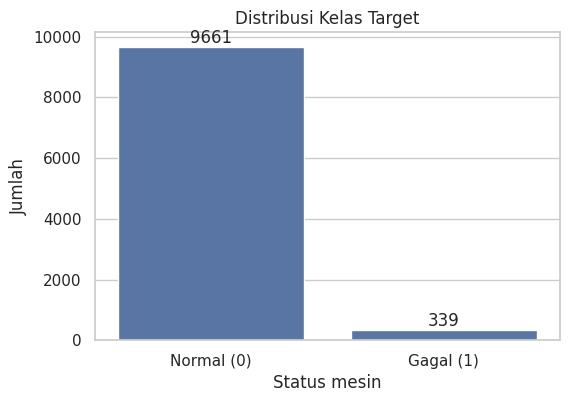

In [5]:
print(df["failure"].value_counts())
print(f"\nPersentase kegagalan: {df['failure'].mean():.2%}")

plt.figure(figsize=(6, 4))
ax = sns.countplot(x="failure", data=df)
ax.bar_label(ax.containers[0])
plt.xticks([0, 1], ["Normal (0)", "Gagal (1)"])
plt.xlabel("Status mesin"); plt.ylabel("Jumlah"); plt.title("Distribusi Kelas Target")
plt.show()

Hanya **339 dari 10.000 mesin (3,39%)** yang gagal, jadi data sangat tidak seimbang. Model yang selalu menebak "normal" sudah akan mencapai akurasi sekitar 96,6%, sehingga akurasi saja tidak cukup untuk menilai model.

### 3.2 Hubungan Fitur dengan Kegagalan

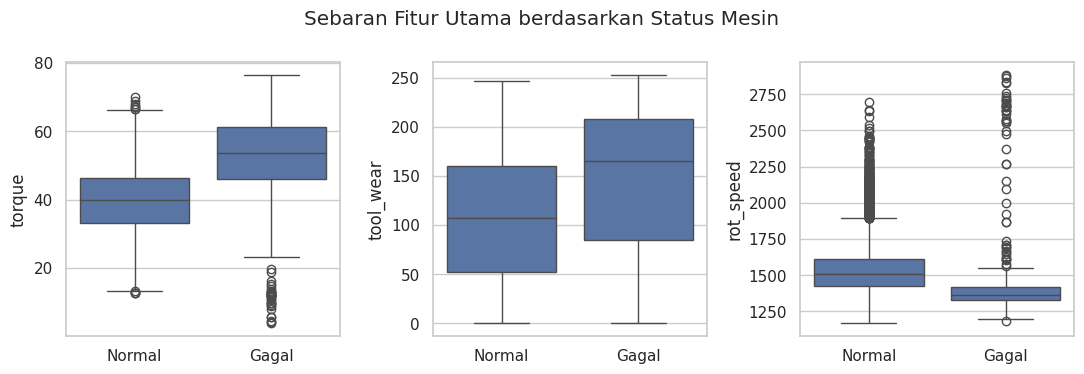

Tingkat kegagalan per tipe produk:
Type
H    0.0209
L    0.0392
M    0.0277
Name: failure, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for a, col in zip(axes, ["torque", "tool_wear", "rot_speed"]):
    sns.boxplot(x="failure", y=col, data=df, ax=a)
    a.set_xticks([0, 1]); a.set_xticklabels(["Normal", "Gagal"]); a.set_xlabel("")
plt.suptitle("Sebaran Fitur Utama berdasarkan Status Mesin"); plt.tight_layout(); plt.show()

print("Tingkat kegagalan per tipe produk:")
print(df.groupby("Type")["failure"].mean().round(4))

Mesin yang gagal cenderung memiliki torsi lebih tinggi, keausan alat lebih besar, dan kecepatan putar lebih rendah. Tingkat kegagalan juga berbeda antar tipe produk (L tertinggi, H terendah).

## 4. Persiapan Data untuk Model
Tipe produk diubah menjadi variabel numerik (one-hot, tipe H sebagai acuan). Data dibagi 80% latih dan 20% uji dengan `stratify` agar proporsi kelas terjaga. Scaling (`StandardScaler`) dilatih **hanya dari data latih**, lalu **SMOTE** diterapkan **hanya pada data latih** supaya data uji tetap murni.

In [7]:
num_cols = ["air_temp", "process_temp", "rot_speed", "torque", "tool_wear"]
X = df[num_cols].copy()
X["Type_L"] = (df["Type"] == "L").astype(int)
X["Type_M"] = (df["Type"] == "M").astype(int)
y = df["failure"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Kegagalan di data latih:", y_train.sum(), "| di data uji:", y_test.sum())

scaler = StandardScaler().fit(X_train[num_cols])
Z_train, Z_test = X_train.copy(), X_test.copy()
Z_train[num_cols] = scaler.transform(X_train[num_cols])
Z_test[num_cols] = scaler.transform(X_test[num_cols])

smote = SMOTE(random_state=42)
Z_res, y_res = smote.fit_resample(Z_train, y_train)
print("\nData latih sebelum SMOTE:", np.bincount(y_train))
print("Data latih sesudah SMOTE :", np.bincount(y_res))

Data latih: (8000, 7) | Data uji: (2000, 7)
Kegagalan di data latih: 271 | di data uji: 68

Data latih sebelum SMOTE: [7729  271]
Data latih sesudah SMOTE : [7729 7729]


## 5. Pelatihan Model
Dua model dilatih untuk perbandingan: **baseline** tanpa penyeimbangan, dan model dengan **SMOTE**.

In [8]:
baseline = LogisticRegression(max_iter=1000, random_state=42).fit(Z_train, y_train)
model = LogisticRegression(max_iter=1000, random_state=42).fit(Z_res, y_res)
print("Model berhasil dilatih.")

Model berhasil dilatih.


## 6. Evaluasi Model

In [9]:
def evaluasi(m, thr=0.5):
    p = m.predict_proba(Z_test)[:, 1]
    pred = (p >= thr).astype(int)
    return {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred), "F1-Score": f1_score(y_test, pred), "AUC": roc_auc_score(y_test, p)}, p, pred

m_base, _, pred_base = evaluasi(baseline)
m_smote, proba, pred = evaluasi(model)
pd.DataFrame({"Baseline (tanpa SMOTE)": m_base, "Model SMOTE": m_smote}).round(3)

,Baseline (tanpa SMOTE),Model SMOTE
Accuracy,0.968,0.832
Precision,0.636,0.148
Recall,0.103,0.824
F1-Score,0.177,0.251
AUC,0.900,0.902


--- Classification Report (Model SMOTE) ---
              precision    recall  f1-score   support

      Normal       0.99      0.83      0.91      1932
       Gagal       0.15      0.82      0.25        68

    accuracy                           0.83      2000
   macro avg       0.57      0.83      0.58      2000
weighted avg       0.96      0.83      0.88      2000



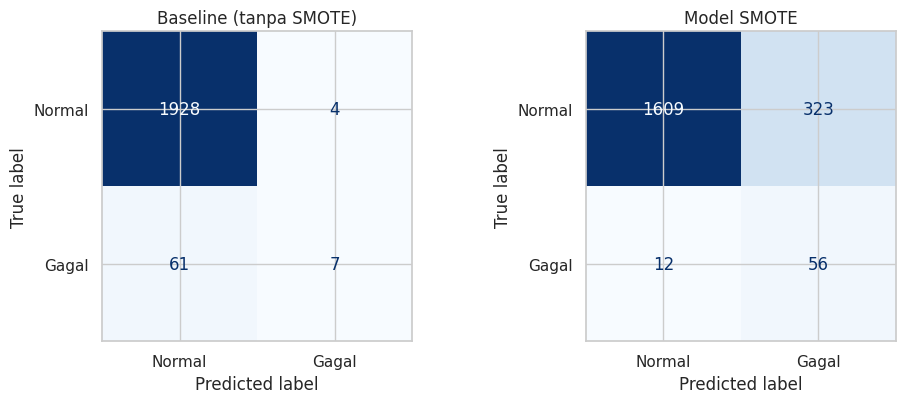

In [10]:
print("--- Classification Report (Model SMOTE) ---")
print(classification_report(y_test, pred, target_names=["Normal", "Gagal"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for a, pr, ttl in zip(axes, [pred_base, pred], ["Baseline (tanpa SMOTE)", "Model SMOTE"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pr), display_labels=["Normal", "Gagal"]).plot(cmap="Blues", ax=a, colorbar=False)
    a.set_title(ttl)
plt.tight_layout(); plt.show()

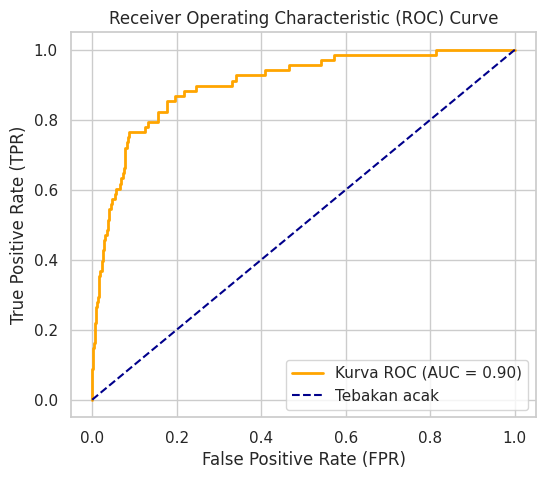

In [11]:
fpr, tpr, _ = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="orange", lw=2, label=f"Kurva ROC (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], "--", color="darkblue", label="Tebakan acak")
plt.xlabel("False Positive Rate (FPR)"); plt.ylabel("True Positive Rate (TPR)")
plt.title("Receiver Operating Characteristic (ROC) Curve"); plt.legend(); plt.grid(True); plt.show()

### Trade-off Threshold

In [12]:
rows = []
for thr in [0.3, 0.5, 0.7, 0.8, 0.9]:
    pr = (proba >= thr).astype(int)
    rows.append({"Threshold": thr, "Precision": precision_score(y_test, pr), "Recall": recall_score(y_test, pr), "F1-Score": f1_score(y_test, pr)})
pd.DataFrame(rows).round(3)

,Threshold,Precision,Recall,F1-Score
0,0.3,0.094,0.897,0.170
1,0.5,0.148,0.824,0.251
2,0.7,0.243,0.721,0.363
3,0.8,0.299,0.559,0.390
4,0.9,0.393,0.353,0.372


## 7. Interpretasi Koefisien

In [13]:
koef = pd.DataFrame({"Fitur": X.columns, "Koefisien": model.coef_[0], "Odds Ratio": np.exp(model.coef_[0])}).round(3)
print("Intercept:", round(model.intercept_[0], 4))
koef.sort_values("Koefisien", ascending=False)

Intercept: -1.0275


,Fitur,Koefisien,Odds Ratio
3,torque,2.549,12.790
0,air_temp,1.979,7.232
2,rot_speed,1.807,6.092
4,tool_wear,0.908,2.480
5,Type_L,-0.474,0.622
6,Type_M,-1.036,0.355
1,process_temp,-1.394,0.248


## 8. Menyimpan Model dan Scaler (Joblib)

In [14]:
joblib.dump(model, "logreg_model.joblib")
joblib.dump(scaler, "scaler.joblib")

# uji muat ulang dan prediksi satu mesin contoh
model_baru, scaler_baru = joblib.load("logreg_model.joblib"), joblib.load("scaler.joblib")
contoh = pd.DataFrame([{"air_temp": 298.9, "process_temp": 309.8, "rot_speed": 1287, "torque": 61.9,
                        "tool_wear": 216, "Type_L": 1, "Type_M": 0}])[X.columns]
contoh[num_cols] = scaler_baru.transform(contoh[num_cols])
p = model_baru.predict_proba(contoh)[0, 1]
print(f"Probabilitas gagal: {p:.1%} -> {'Berisiko Gagal' if p >= 0.5 else 'Tidak Berisiko'}")

Probabilitas gagal: 90.0% -> Berisiko Gagal


## 9. Analisis Hasil
**Akurasi bisa menyesatkan.** Model baseline tampak bagus (akurasi 0,968), tetapi Recall-nya hanya 0,103: dari 68 mesin yang benar-benar gagal pada data uji, hanya 7 yang terdeteksi dan 61 terlewat. Model seperti ini tidak berguna untuk pemeliharaan.

**SMOTE meningkatkan Recall.** Dengan SMOTE, Recall naik menjadi 0,824 (56 dari 68 kegagalan terdeteksi, 12 terlewat). Harganya, Precision turun menjadi 0,148: dari 379 peringatan, 323 adalah alarm palsu. Akurasi turun ke 0,832 karena banyak mesin normal diperiksa tanpa perlu. AUC hampir tidak berubah (sekitar 0,90) karena kemampuan model membedakan kedua kelas relatif sama; yang berubah adalah titik potong keputusannya.

**Metrik yang dipilih: Recall.** Bagi pabrik, **False Negative** (kegagalan yang terlewat) berarti mesin mati mendadak, produksi terhenti, dan biaya perbaikan darurat. **False Positive** hanya berarti pemeriksaan tambahan yang relatif murah. Karena itu Recall diprioritaskan, dengan Precision yang rendah sebagai konsekuensi yang dapat diterima. Tabel threshold menunjukkan bahwa menaikkan ambang batas ke 0,8 menaikkan Precision menjadi sekitar 0,30 tetapi Recall turun menjadi sekitar 0,56; pilihan akhir bergantung pada biaya pemeriksaan versus biaya kegagalan.

**Koefisien.** Torsi memiliki koefisien terbesar (sekitar 2,55): kenaikan torsi sebesar satu simpangan baku (sekitar 10 Nm) menaikkan odds kegagalan sekitar 12,8 kali. Suhu udara, kecepatan putar, dan keausan alat juga bernilai positif, sedangkan suhu proses bernilai negatif karena yang berpengaruh pada kegagalan pendinginan adalah selisihnya dengan suhu udara. Tipe produk M dan L memiliki koefisien negatif terhadap acuan H setelah variabel lain dikendalikan.

**Keterbatasan.**
1. Dataset bersifat sintetis, sehingga hasilnya belum tentu sama pada mesin sebenarnya.
2. Kegagalan pada data ini ditentukan oleh aturan non-linear (misalnya selisih suhu, hasil kali torsi dan keausan, serta daya dari torsi dan kecepatan putar), sedangkan Regresi Logistik hanya membuat batas keputusan linear. Itu sebabnya AUC berhenti di sekitar 0,90. Menambah fitur turunan atau memakai model non-linear (Random Forest, Gradient Boosting) kemungkinan memperbaiki hasil.
3. SMOTE membuat data sintetis, termasuk pada kolom one-hot tipe produk yang menjadi bernilai pecahan; varian `SMOTENC` lebih tepat untuk fitur campuran.
4. Data uji hanya memuat 68 kegagalan, sehingga metrik dapat berubah jika pembagian data berbeda.

**Kesimpulan.** Regresi Logistik dengan SMOTE berhasil mendeteksi 82,4% kegagalan mesin pada data uji dengan AUC 0,90. Model ini cocok sebagai sistem peringatan dini yang sensitif, dengan catatan jumlah alarm palsu yang tinggi dan hasil yang masih perlu dikonfirmasi oleh teknisi.

## Referensi
- Matzka, S. (2020). *AI4I 2020 Predictive Maintenance Dataset*. UCI Machine Learning Repository. https://doi.org/10.24432/C5HS5C
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2013). *An Introduction to Statistical Learning*. Springer.
- Dokumentasi scikit-learn dan imbalanced-learn.